# fal Video Family Walkthrough

<p align="center">
  <img src="../../.github/images/banners/fal-video-family-walkthrough.png" alt="fal Video Family Walkthrough: five video models, one Contoso Outdoors launch campaign" width="900" />
</p>

Five fal video models on Microsoft Foundry, each doing the job it does best, then cut together into one campaign reel.

| | |
|---|---|
| Models | [Kling V3 Pro](../../4-models/fal-kling-v3-pro/) · [LTX 2.5 Pro](../../4-models/fal-ltx-2.5-pro/) · [LTX 2.5 Fast](../../4-models/fal-ltx-2.5-fast/) · [MiniMax H3 Max](../../4-models/fal-minimax-h3-max/) · [MiniMax H3 Max Turbo](../../4-models/fal-minimax-h3-max-turbo/) |
| Released | 2026-11-06 (preview) |
| Publisher | fal (models by Kling, Lightricks, and MiniMax) |
| Capability | [Video Generation](../../3-primers/video-generation.md) |
| Announcement | [Release post](https://techcommunity.microsoft.com/blog/azure-ai-foundry-blog/building-the-next-generation-of-multimodal-ai-experiences-with-fal-in-microsoft-/4570032) |
| Docs | [Fal models on Microsoft Foundry](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models) |
| Deployments | All five in one Foundry project. Kling needs a US Data Zone region |
| Rate limit | 2 requests per minute per deployment on quota tiers 1–4 |
| Pricing | Not on the model cards yet. Check each deployment in the Foundry portal |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT`, `AZURE_FAL_KLING_V3_PRO_DEPLOYMENT`, `AZURE_FAL_LTX_25_PRO_DEPLOYMENT`, `AZURE_FAL_LTX_25_FAST_DEPLOYMENT`, `AZURE_FAL_MINIMAX_H3_MAX_DEPLOYMENT`, `AZURE_FAL_MINIMAX_H3_MAX_TURBO_DEPLOYMENT`, `DEMO_MODE`, `PLAY_INLINE` |

**Read first:** the [Video Generation primer](../../3-primers/video-generation.md) explains the terms we use here (multi-shot, reference-to-video, first and last frame, native audio). Each model also has its own capsule, linked above, that goes deeper.

> **Replay or live?** This notebook opens in **replay** mode (`DEMO_MODE=replay`): it shows clips we already made and makes no Azure calls. Replay clips are **compressed copies** (about 480p) to keep the repo small, so expect less detail than a live run; the facts printed under each clip describe the original. Switch to `DEMO_MODE=live` in `.env`, or set `DEMO_MODE = "live"` in the env check cell, once the deployments are ready and you want to make your own clips. See **Before you start** below.

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Contoso Outdoors needs a launch campaign: a hero spot, product shots, social cuts, and a store loop. Which fal video model should make each piece?"*

The five fal models overlap, but each has a job it does best. We give all five the same brief first, then hand each one the work it's built for, and finish by cutting the results into one 30-second reel. We use the [Contoso Outdoors scenario](../../2-scenarios/contoso-retail/) where the real product matters, and other subjects where they show a capability better.

## What We Will Do

- Give all five models the same brief and compare speed, look, and sound
- Hand each model its specialty: multi-shot dialogue, physics, sharp text and motion, long and 4K takes, real products in one scene
- Check whether the fast tier is good enough for drafts
- Cut the best clips into one campaign reel and decide when to choose each model

> Run each cell with **Shift + Enter**. Guess first: before each video, predict one thing it will get right and one it will get wrong.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows clips saved in `output/` (yours) or `examples/` (ours) and makes no Azure calls.

**Running it live?** We need:

1. **fal enabled on the subscription.** An admin registers the **Fal.EnableDeploy** preview feature ([steps](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models#enable-fal-on-foundry)).
2. **All five deployments** in our Foundry project ([steps](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models#deploy-fal-models-from-the-foundry-portal)).
3. **A sign-in with a Foundry role** on the resource: run `az login`. We use keyless Microsoft Entra ID tokens.
4. **`.env` at the repo root** with the variables above and `DEMO_MODE=live`. See [sample.env](../../1-scripts/sample.env).

A full live run makes 15 clips, at about 2 requests a minute per model. Set `PLAY_INLINE=false` to keep the notebook small: each clip still gets a frame strip and a link to its MP4.

**Data handling.** fal hosts these models outside Microsoft. Prompts and images we send leave Microsoft, and Microsoft's product terms and DPA don't apply. We only send fictional Contoso data and generated images.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "fal_video.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "").strip()
RPM = int(os.getenv("FAL_REQUESTS_PER_MINUTE", "2"))
PLAY_INLINE = os.getenv("PLAY_INLINE", "false").strip().lower() == "true"

DEPLOYMENT_VARS = {
    "kling": ("AZURE_FAL_KLING_V3_PRO_DEPLOYMENT", "Fal-Kling-V3-Pro"),
    "ltx-pro": ("AZURE_FAL_LTX_25_PRO_DEPLOYMENT", "Fal-LTX-2.5-Pro"),
    "ltx-fast": ("AZURE_FAL_LTX_25_FAST_DEPLOYMENT", "Fal-LTX-2.5-Fast"),
    "h3-max": ("AZURE_FAL_MINIMAX_H3_MAX_DEPLOYMENT", "Fal-MiniMax-H3-Max"),
    "h3-turbo": ("AZURE_FAL_MINIMAX_H3_MAX_TURBO_DEPLOYMENT", "Fal-MiniMax-H3-Max-Turbo"),
}
DEPLOYMENTS = {key: (os.getenv(var) or default).strip() for key, (var, default) in DEPLOYMENT_VARS.items()}

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("MICROSOFT_FOUNDRY_ENDPOINT is missing from .env. Run setup.ipynb, or copy it from the project's Overview page.")
    unset = [var for var, _ in DEPLOYMENT_VARS.values() if not os.getenv(var)]
    if unset:
        print(f"Not in .env, so using the catalog name as the deployment name: {', '.join(unset)}")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | {RPM} requests per minute per deployment | inline players: {PLAY_INLINE}")
for key, name in DEPLOYMENTS.items():
    print(f"   {key:9} {name}")

Mode: live | 2 requests per minute per deployment | inline players: False
   kling     Fal-Kling-V3-Pro
   ltx-pro   Fal-LTX-2.5-Pro
   ltx-fast  Fal-LTX-2.5-Fast
   h3-max    Fal-MiniMax-H3-Max
   h3-turbo  Fal-MiniMax-H3-Max-Turbo


The shared helper in [1-scripts/fal_video.py](../../1-scripts/fal_video.py) submits each job, polls until it's done, downloads the MP4, and saves a JSON record. We make one helper per deployment, so each keeps its own rate limit, and all five save into this notebook's `output/` folder.

In [2]:
sys.path.insert(0, str(ROOT / "1-scripts"))
from fal_video import Clip, FalVideo, _ffmpeg, as_url, probe, scoreboard
from IPython.display import Image as Picture, display

HERE = ROOT / "5-multi-model" / "fal-video-family-walkthrough"
IMAGES = ROOT / "2-scenarios" / "contoso-retail" / "data" / "generated" / "images"
FAMILIES = {"kling": "kling/v3/pro", "ltx-pro": "lightricks/ltx-2.5", "ltx-fast": "lightricks/ltx-2.5",
            "h3-max": "minimax/h3-max", "h3-turbo": "minimax/h3-max-turbo"}

fal = {key: FalVideo(ENDPOINT, DEPLOYMENTS[key], family=family, here=HERE, mode=MODE,
                     requests_per_minute=RPM, play_inline=PLAY_INLINE, credential=credential)
       for key, family in FAMILIES.items()}
show = fal["kling"].show
clips = []
SEED = 2026  # MiniMax takes a seed; the others don't
TENT = "the TrailMaster X4, a four-person dome tent with a forest-green body under a burnt-orange rainfly"

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. Same brief, five models: what's different?

One shot, written once, sent to all five at the closest settings each allows: 6 seconds, about 720p, 16:9, audio on. Nothing here is tuned for any model, so this is the baseline.

> 🔮 **Guess first:** which model will finish first? Which one will get the tent's colors right?

   Submitted 01-brief-kling (71874219...)............................................. done in 258 s
   Submitted 01-brief-ltx-pro (41d41546...)...................................................... done in 309 s
   Submitted 01-brief-ltx-fast (50231b6a...)............... done in 87 s
   Submitted 01-brief-h3-max (d7e52531...)... done in 19 s
   Submitted 01-brief-h3-turbo (96281b5f...)... done in 19 s
01-brief-kling: 1920x1080 | 6.0 s | 24 fps | audio | made in 258 s | (example)


▶️ [01-brief-kling.mp4](examples/01-brief-kling.mp4)

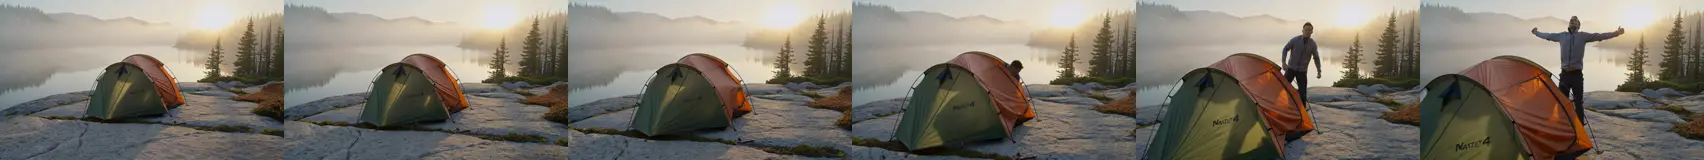

01-brief-ltx-pro: 1280x720 | 6.0 s | 25 fps | audio | made in 309 s | (example)


▶️ [01-brief-ltx-pro.mp4](examples/01-brief-ltx-pro.mp4)

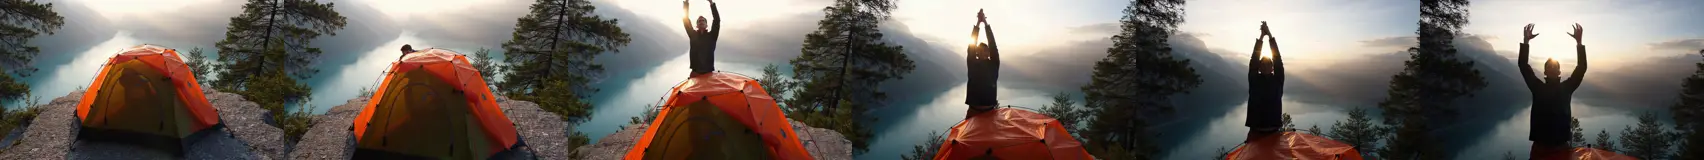

01-brief-ltx-fast: 1280x720 | 6.0 s | 25 fps | audio | made in 87 s | (example)


▶️ [01-brief-ltx-fast.mp4](examples/01-brief-ltx-fast.mp4)

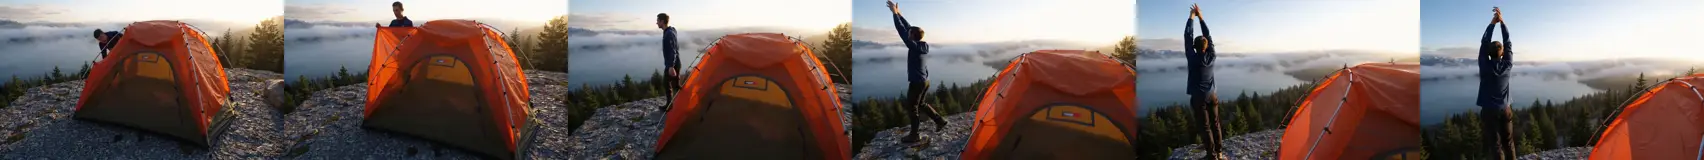

01-brief-h3-max: 1344x768 | 6.6 s | 24 fps | audio | made in 19 s | (example)


▶️ [01-brief-h3-max.mp4](examples/01-brief-h3-max.mp4)

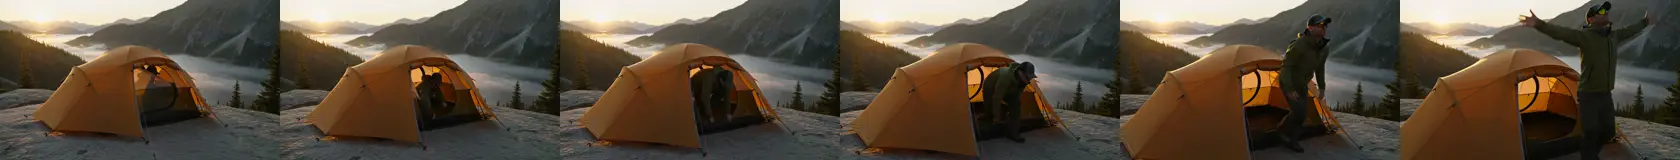

01-brief-h3-turbo: 1344x768 | 6.6 s | 24 fps | audio | made in 19 s | (example)


▶️ [01-brief-h3-turbo.mp4](examples/01-brief-h3-turbo.mp4)

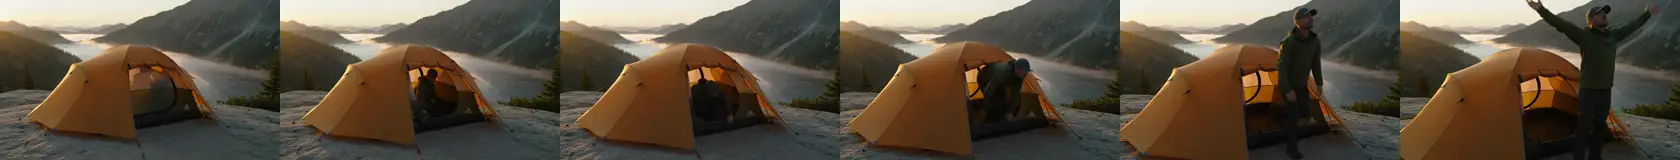

clip                                made in  asked    got       size   fps     MB audio
01-brief-kling                      257.6 s      6   6.04  1920x1080  24.0  24.18 yes
01-brief-ltx-pro                    308.8 s      6    6.0   1280x720  25.0   5.59 yes
01-brief-ltx-fast                    87.2 s      6    6.0   1280x720  25.0    3.0 yes
01-brief-h3-max                      18.8 s      6   6.59   1344x768  24.0   8.41 yes
01-brief-h3-turbo                    19.0 s      6   6.59   1344x768  24.0   8.35 yes


In [3]:
BRIEF = f"""Medium shot of {TENT}, pitched on a granite ledge above a misty alpine lake at sunrise.
A hiker unzips the door, steps out, and stretches. Slow dolly in. Soft golden light.
Audio: birds, the zipper, wind in the pines, no music."""

LTX = dict(duration=6, resolution="720p", fps=25, aspect_ratio="16:9")
H3 = dict(prompt_expansion_mode="disabled", seed=SEED, duration=6, resolution="768P", aspect_ratio="16:9")

same_brief = [
    fal["kling"].run("01-brief-kling", "text-to-video", prompt=BRIEF, duration="6", aspect_ratio="16:9"),
    fal["ltx-pro"].run("01-brief-ltx-pro", "text-to-video/pro", prompt=BRIEF, **LTX),
    fal["ltx-fast"].run("01-brief-ltx-fast", "text-to-video/fast", prompt=BRIEF, **LTX),
    fal["h3-max"].run("01-brief-h3-max", "text-to-video", prompt=BRIEF, **H3),
    fal["h3-turbo"].run("01-brief-h3-turbo", "text-to-video", prompt=BRIEF, **H3),
]
clips += same_brief
show(*same_brief, frames=6)
scoreboard(same_brief)

**What to look for:** the "made in" column first: that's what a draft loop costs us in waiting. Then the tent: green body, orange rainfly, granite ledge. Then the order of events (zip, step out, stretch) and whether the zipper sound lands with the zipper. Each model has a different default look; the rest of the notebook plays to each one's strength.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Can one request direct a multi-shot scene with two speakers?

Kling 3.0 is the storyboard model. With `multi_prompt` we set each shot's size, camera, and length, and it keeps the characters distinct across cuts. We also test a claim from the release: characters in one scene can speak different languages. One hiker speaks English, the other Spanish.

> 🔮 **Guess first:** Kling's API docs say speech other than Chinese and English is translated to English. Will Lucía's line come out in Spanish?

   Submitted 02-kling-multishot-dialogue (f88a3c5e...)............................................................. done in 349 s
02-kling-multishot-dialogue: 1920x1080 | 12.1 s | 24 fps | audio | made in 348 s | (example)


▶️ [02-kling-multishot-dialogue.mp4](examples/02-kling-multishot-dialogue.mp4)

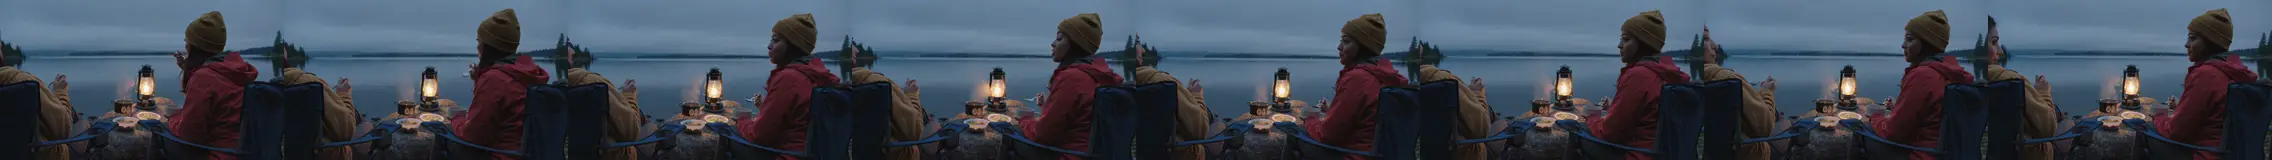

In [4]:
CAMP_TALK = ("Two hikers share dinner at a lakeside camp at dusk. Maya, in a red jacket, speaks English. "
             "Lucía, in a yellow beanie, answers in Spanish. Audio: stove hiss, crickets, their voices.")
SHOTS = [
    {"prompt": "Wide shot at eye level: two hikers sit by a camping stove outside a green tent at dusk, the lake behind them. Audio: stove hiss, crickets.", "duration": "4"},
    {"prompt": 'Medium close-up over Lucía\'s shoulder on Maya, in a red jacket. She says: "the forecast says rain tonight." Slow push in.', "duration": "4"},
    {"prompt": 'Medium close-up on Lucía, in a yellow beanie, smiling. She answers in Spanish: "mejor. me encanta la lluvia en la tienda." Rack focus to the lake behind her.', "duration": "4"},
]
talk = fal["kling"].run("02-kling-multishot-dialogue", "text-to-video", prompt=CAMP_TALK, multi_prompt=SHOTS,
                        shot_type="customize", duration="12", aspect_ratio="16:9")
clips.append(talk)
show(talk, frames=8)

**What to look for:** cuts near 4 s and 8 s, and the shot sizes we asked for. Maya stays in red and Lucía in yellow across the cuts. Lip sync on each line, and which language Lucía actually speaks. If it comes out in English, use a separate voice track for localized lines (see the [Audio / Speech primer](../../3-primers/audio-speech.md)).

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. Does the motion look physically real?

Kling is also tuned for cinematic camera moves (rack focus, dolly zoom) and natural cloth, hair, and liquid. We don't need a product for this, so the shot is built around the hardest physics we can name: coffee poured in the wind, in the rain.

   Submitted 03-kling-physics (2c85f2f1...)................................ done in 183 s
03-kling-physics: 1920x1080 | 5.0 s | 24 fps | audio | made in 183 s | (example)


▶️ [03-kling-physics.mp4](examples/03-kling-physics.mp4)

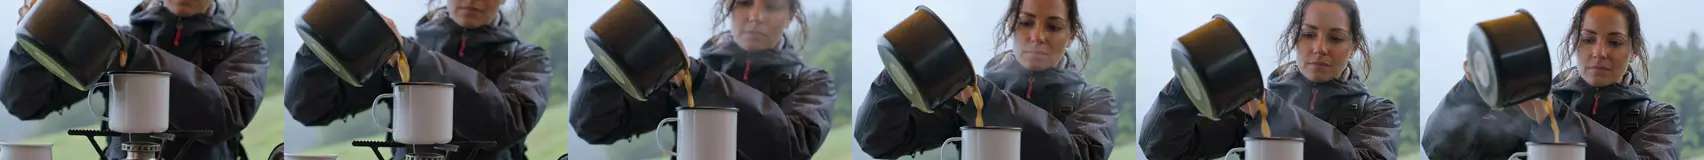

In [5]:
PHYSICS = """Close-up in light rain and gusty wind: a hiker pours steaming coffee from a small pot on a camping stove into an enamel mug.
The stream of coffee bends in the wind, steam whips sideways, rain beads on her jacket, loose hair blows across her face.
Rack focus from the mug to her face, then a slow dolly zoom. Audio: rain on fabric, wind gusts, coffee pouring."""

pour = fal["kling"].run("03-kling-physics", "text-to-video", prompt=PHYSICS, duration="5", aspect_ratio="16:9")
clips.append(pour)
show(pour, frames=6)

**What to look for:** does the coffee stream bend *with* the wind, and land in the mug? Does steam move the same way as the hair? Does the focus actually shift from the mug to her face? Liquids and hair are where generated video most often looks wrong, so this is a quick quality check for any video model.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Do text, crowds, and fast motion stay sharp?

LTX 2.5 Pro decodes with a diffusion video decoder for sharper faces, readable on-screen text, and fewer smears in fast motion, and spends more compute on busy scenes. We test both: the launch poster with its tagline, and a crowded trail-race start at 50 fps.

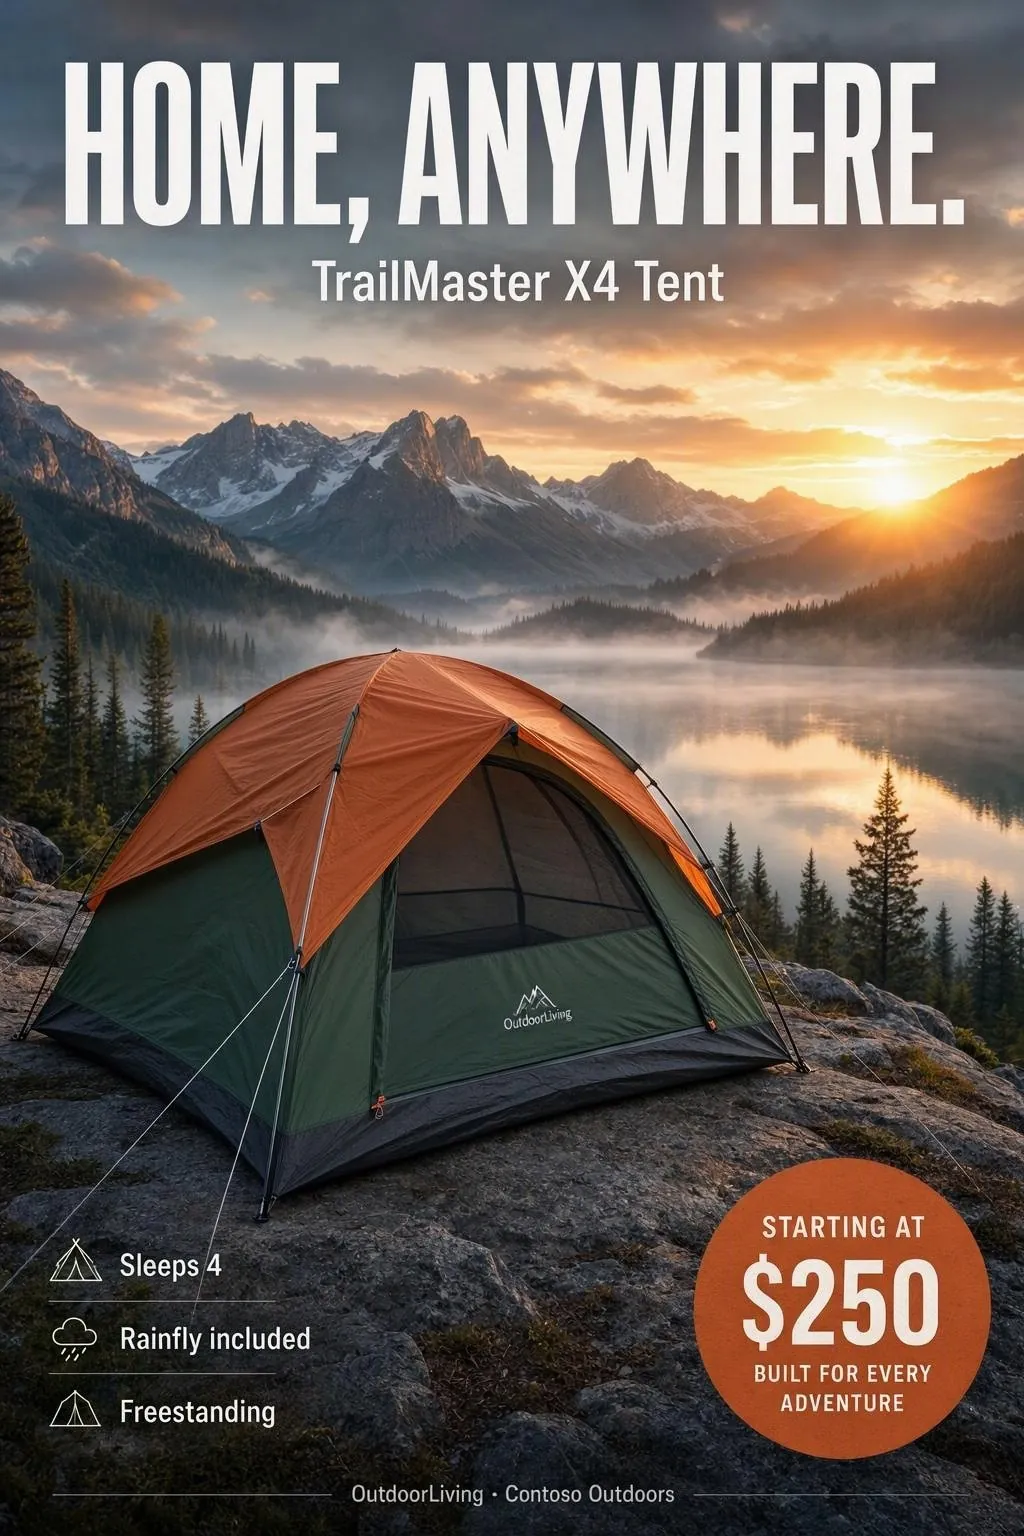

   Submitted 04-ltx-pro-poster-text (973c8479...)................ done in 92 s
   Submitted 04-ltx-pro-crowd-motion (29f4bd5e...)............................................................... done in 360 s
04-ltx-pro-poster-text: 1080x1920 | 6.0 s | 25 fps | no audio | made in 92 s | (example)


▶️ [04-ltx-pro-poster-text.mp4](examples/04-ltx-pro-poster-text.mp4)

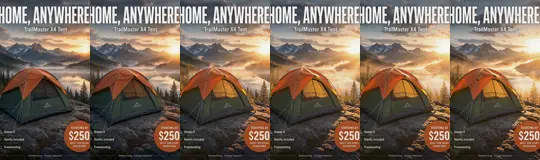

04-ltx-pro-crowd-motion: 1920x1080 | 6.0 s | 50 fps | audio | made in 360 s | (example)


▶️ [04-ltx-pro-crowd-motion.mp4](examples/04-ltx-pro-crowd-motion.mp4)

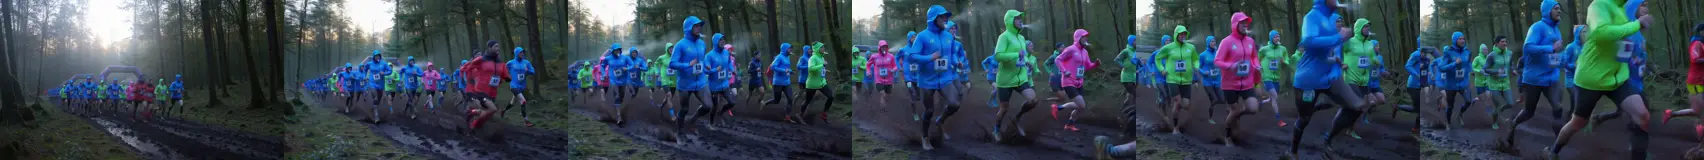

In [6]:
display(Picture(filename=str(IMAGES / "launch-poster.webp"), width=200))

poster = fal["ltx-pro"].run("04-ltx-pro-poster-text", "image-to-video/pro", image_url=as_url(IMAGES / "launch-poster.webp"),
                            prompt="Mist drifts slowly across the lake behind the tent; the sunrise light brightens. All text stays exactly as it is.",
                            camera_motion="static", duration=6, resolution="1080p", aspect_ratio="9:16", generate_audio=False)

RACE = """Trail race start at dawn: about fifty runners in bright jackets burst from a start arch onto a muddy forest trail,
mud splashing, bib numbers flapping, breath visible in the cold air. Low tracking shot alongside the leaders.
Audio: a starting horn, the crowd cheering, footsteps in mud."""
race = fal["ltx-pro"].run("04-ltx-pro-crowd-motion", "text-to-video/pro", prompt=RACE, duration=6, resolution="1080p", fps=50, aspect_ratio="16:9")

clips += [poster, race]
show(poster, race, frames=6)

**What to look for:** read "HOME, ANYWHERE." in every frame of the poster: letters that wobble or melt are the first sign of a weak decoder. In the race, pick one runner and follow them: faces, bib numbers, and legs should stay intact, and mud should fly rather than smear. Crowds are where the extra compute shows.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 5. How long and how big can one take be?

LTX 2.5 Fast is the volume and size model: up to 20 seconds in one take at 720p or 1080p, and 4K (2160p) for up to 10 seconds. We make the day-to-night establishing shot for the reel, and a silent 4K loop for an in-store screen.

   Submitted 05-ltx-fast-twenty-seconds (c8907798...)............................. done in 168 s
   Submitted 05-ltx-fast-4k-loop (76c09877...)............................................. done in 257 s
05-ltx-fast-twenty-seconds: 1280x720 | 20.0 s | 24 fps | audio | made in 168 s | (example)


▶️ [05-ltx-fast-twenty-seconds.mp4](examples/05-ltx-fast-twenty-seconds.mp4)

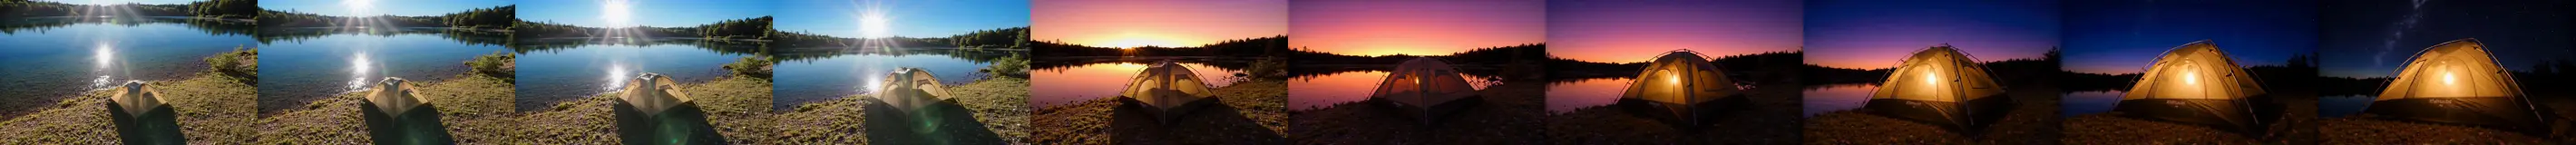

05-ltx-fast-4k-loop: 3840x2160 | 6.0 s | 25 fps | no audio | made in 257 s | (example)


▶️ [05-ltx-fast-4k-loop.mp4](examples/05-ltx-fast-4k-loop.mp4)

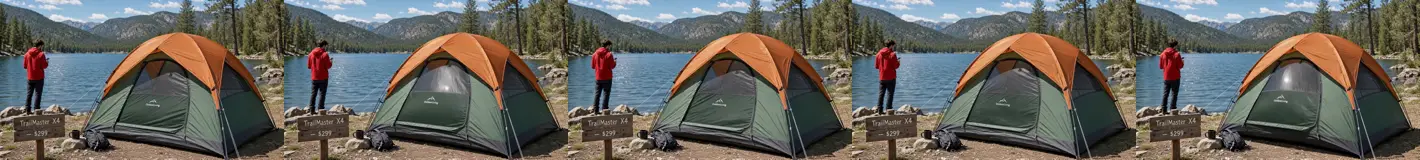

In [7]:
DAY_TO_NIGHT = ("One continuous take: the TrailMaster X4 tent beside a lake, from bright afternoon through sunset to a starry night. "
                "Shadows lengthen, the sky turns orange then deep blue, a lantern glows inside the tent. Very slow dolly in. "
                "Audio: birds fading into crickets, gentle water.")
long_take = fal["ltx-fast"].run("05-ltx-fast-twenty-seconds", "text-to-video/fast", prompt=DAY_TO_NIGHT,
                                duration=20, resolution="720p", fps=24, aspect_ratio="16:9")

store_loop = fal["ltx-fast"].run("05-ltx-fast-4k-loop", "image-to-video/fast", image_url=as_url(IMAGES / "campsite-before.webp"),
                                 prompt="Gentle ripples cross the lake; leaves sway; the tent fabric breathes in the breeze. Static camera.",
                                 duration=6, resolution="2160p", fps=25, generate_audio=False)
clips += [long_take, store_loop]
show(long_take, frames=10)
show(store_loop)

**What to look for:** in the long take, the light should change smoothly with no jump, and the tent should stay the same tent for 20 seconds. In the 4K loop, check the "made in" time and file size against section 1: big outputs cost time and storage, so save 4K for screens that need it.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 6. Can real products share one scene, in order, in a set style?

MiniMax H3 Max takes up to 9 reference images and names them in the prompt as **Image 1**, **Image 2**, and so on. It's tuned to hit beats in the order written and to hold an art direction. We put four real products in one scene, then tell a story in claymation that ends on legible on-screen text.

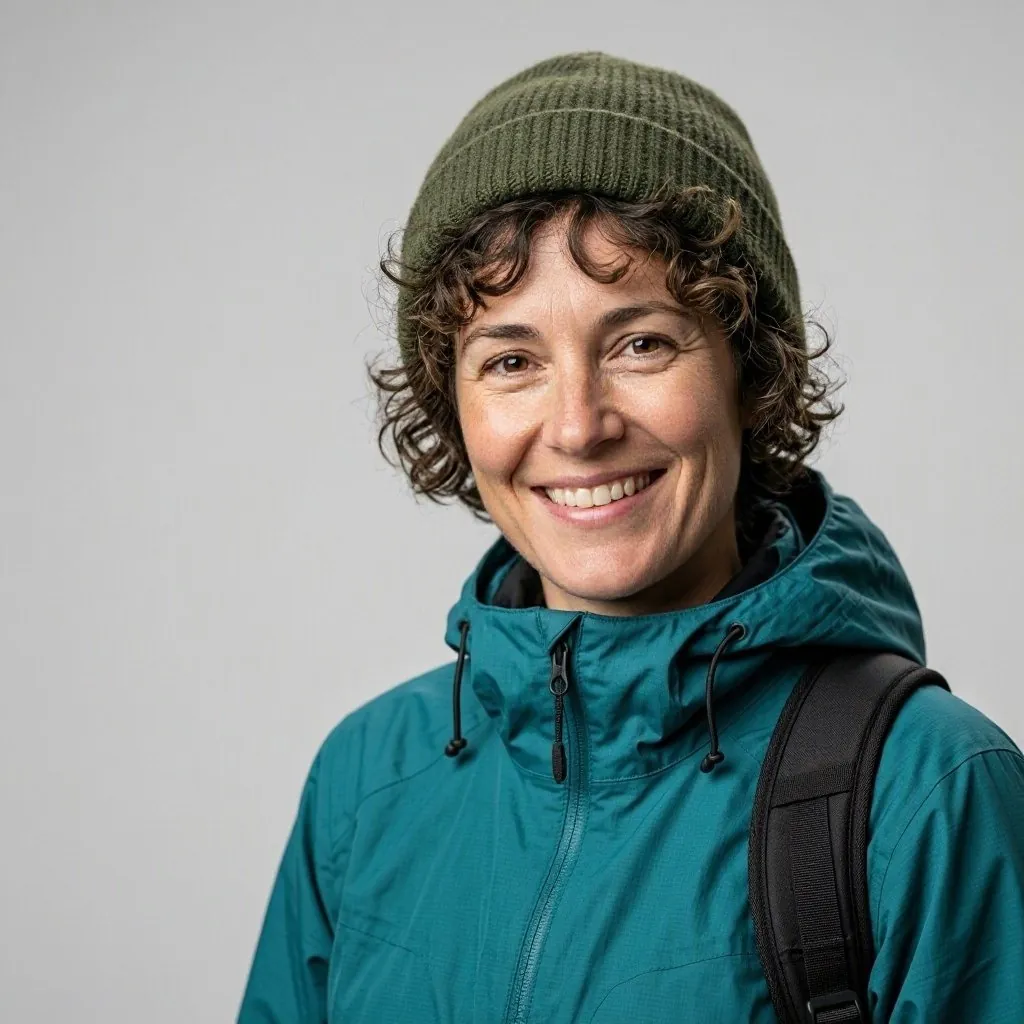

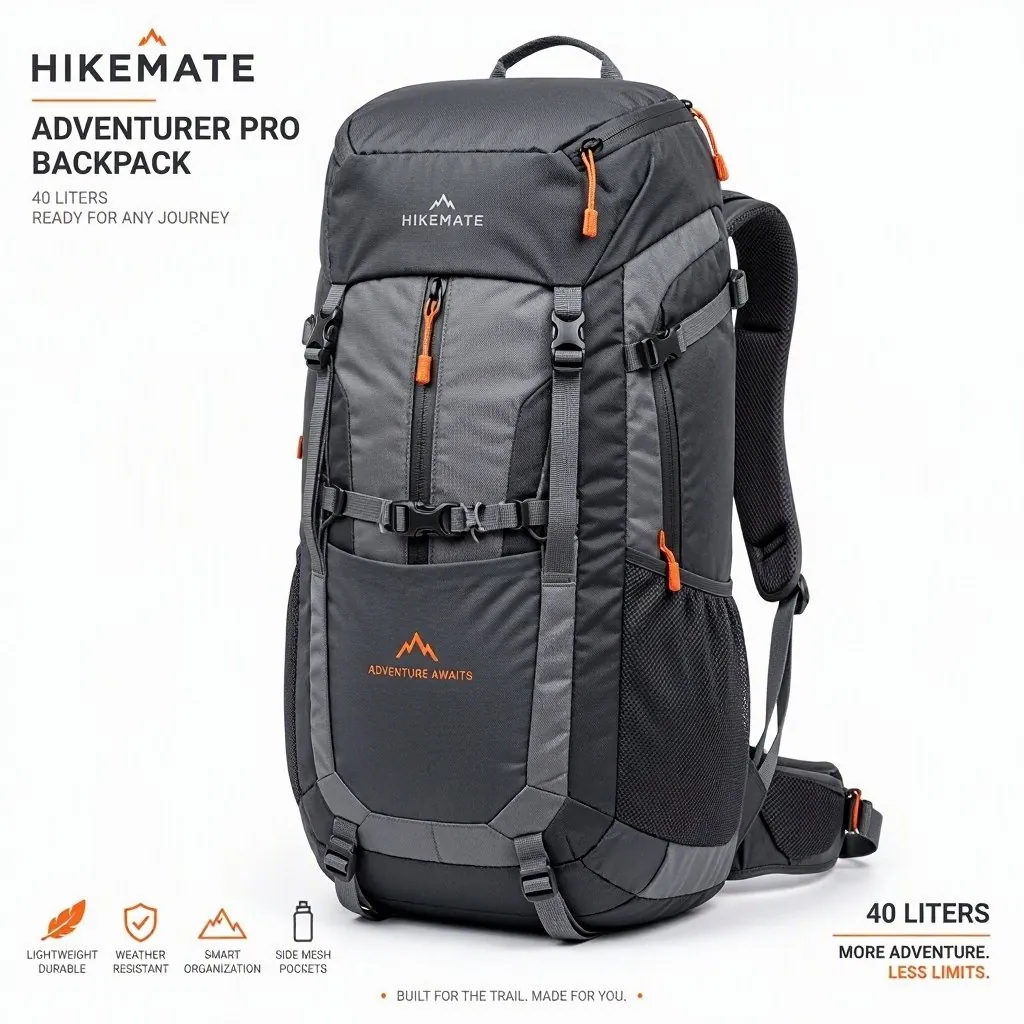

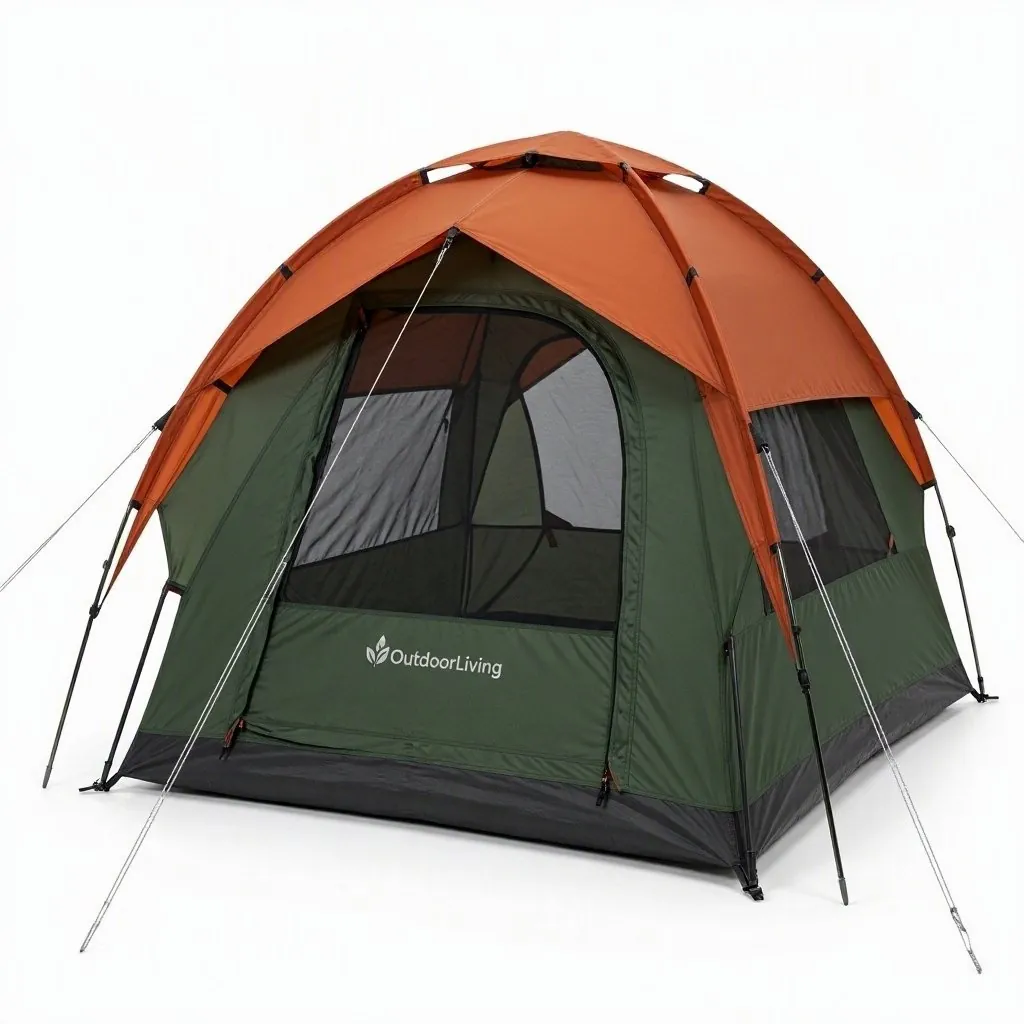

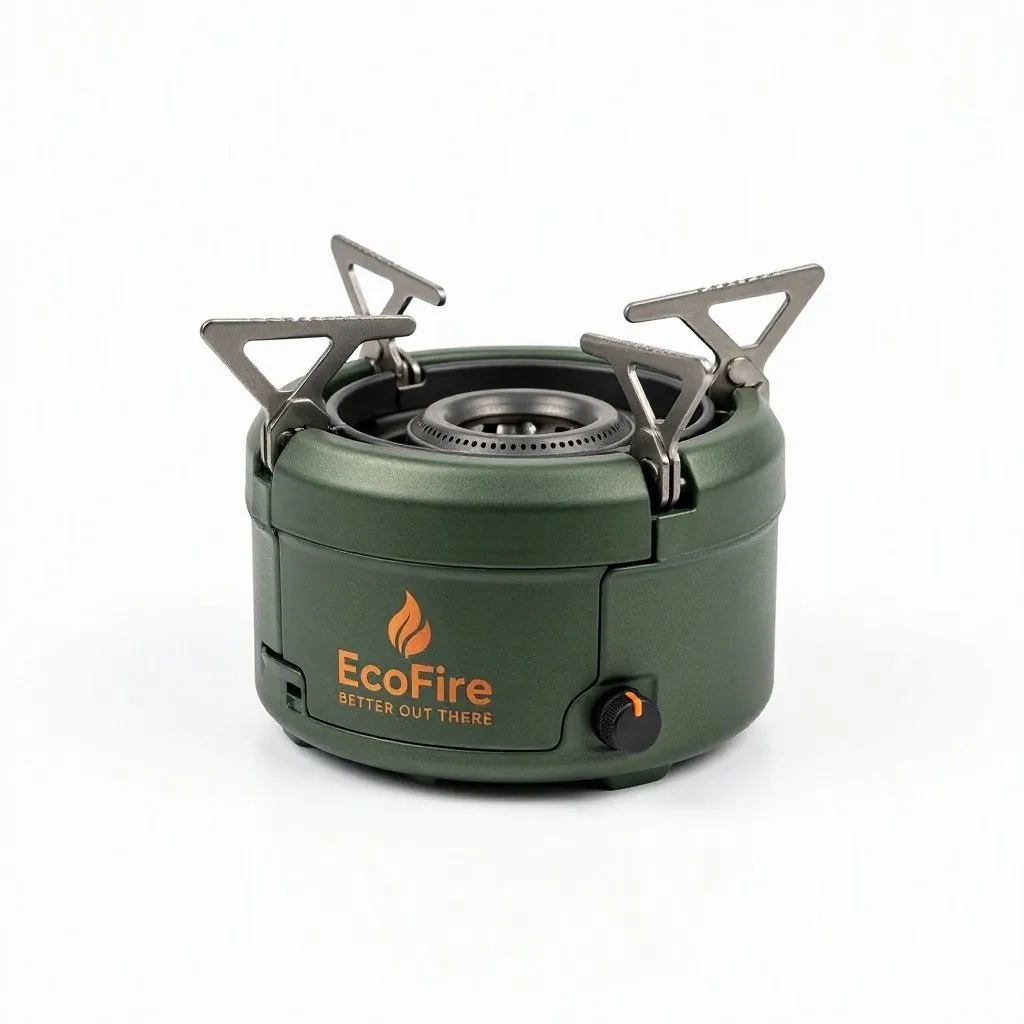

   Submitted 06-h3-max-four-products (d34dcc34...)... done in 19 s
   Waiting 10 s for the rate limit (2 requests a minute)...
   Submitted 06-h3-max-claymation-text (662890dd...)... done in 19 s
06-h3-max-four-products: 1344x768 | 8.0 s | 24 fps | audio | made in 19 s | (example)


▶️ [06-h3-max-four-products.mp4](examples/06-h3-max-four-products.mp4)

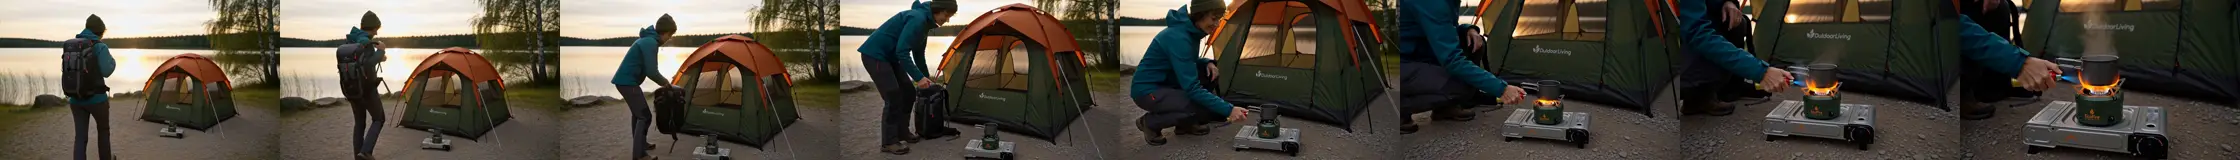

06-h3-max-claymation-text: 1344x768 | 6.6 s | 24 fps | audio | made in 19 s | (example)


▶️ [06-h3-max-claymation-text.mp4](examples/06-h3-max-claymation-text.mp4)

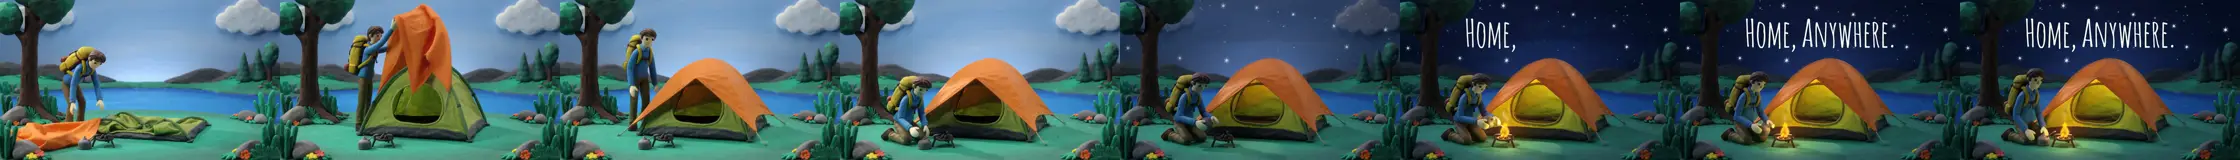

In [8]:
CAST = ["prop-hiker", "prop-backpack", "prop-tent", "prop-stove"]
display(*[Picture(filename=str(IMAGES / f"{name}.webp"), width=140) for name in CAST])

WEEKEND = """The hiker from Image 1, wearing the backpack from Image 2, arrives at a lakeside campsite in late afternoon.
The hiker sets down the pack beside the tent from Image 3, already pitched, and lights the stove from Image 4; a small pot starts to steam.
Medium tracking shot that ends on a close-up of the stove. Warm light.
Audio: footsteps on gravel, the click and hiss of the stove, birds."""
weekend = fal["h3-max"].run("06-h3-max-four-products", "reference-to-video", prompt=WEEKEND, prompt_expansion_mode="disabled",
                            reference_image_urls=[as_url(IMAGES / f"{name}.webp") for name in CAST],
                            seed=SEED, duration=8, resolution="768P", aspect_ratio="16:9")

CLAY = """Stop-motion claymation, visible fingerprints in the clay. In this order: a clay hiker pitches a green tent with an orange rainfly beside a lake;
the hiker lights a small stove; the sky turns to night and stars appear; the words "HOME, ANYWHERE." appear in white letters above the tent.
Static camera. Audio: a gentle music box melody, crickets."""
clay_max = fal["h3-max"].run("06-h3-max-claymation-text", "text-to-video", prompt=CLAY, **H3)

clips += [weekend, clay_max]
show(weekend, clay_max, frames=8)

**What to look for:** product by product, does each match its reference image? Then the order of events: arrive, set down, light; pitch, light, night, text. In the claymation clip, the style should hold in every frame (no slide back to photorealism) and the words should be spelled right.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 7. Can we land on our exact first and last frames?

When a brand needs a clip to open and close on approved images, we fix both ends with `image_url` and `end_image_url` and the model invents only the motion between them. Our pair is the campsite before and after a new rainfly color.

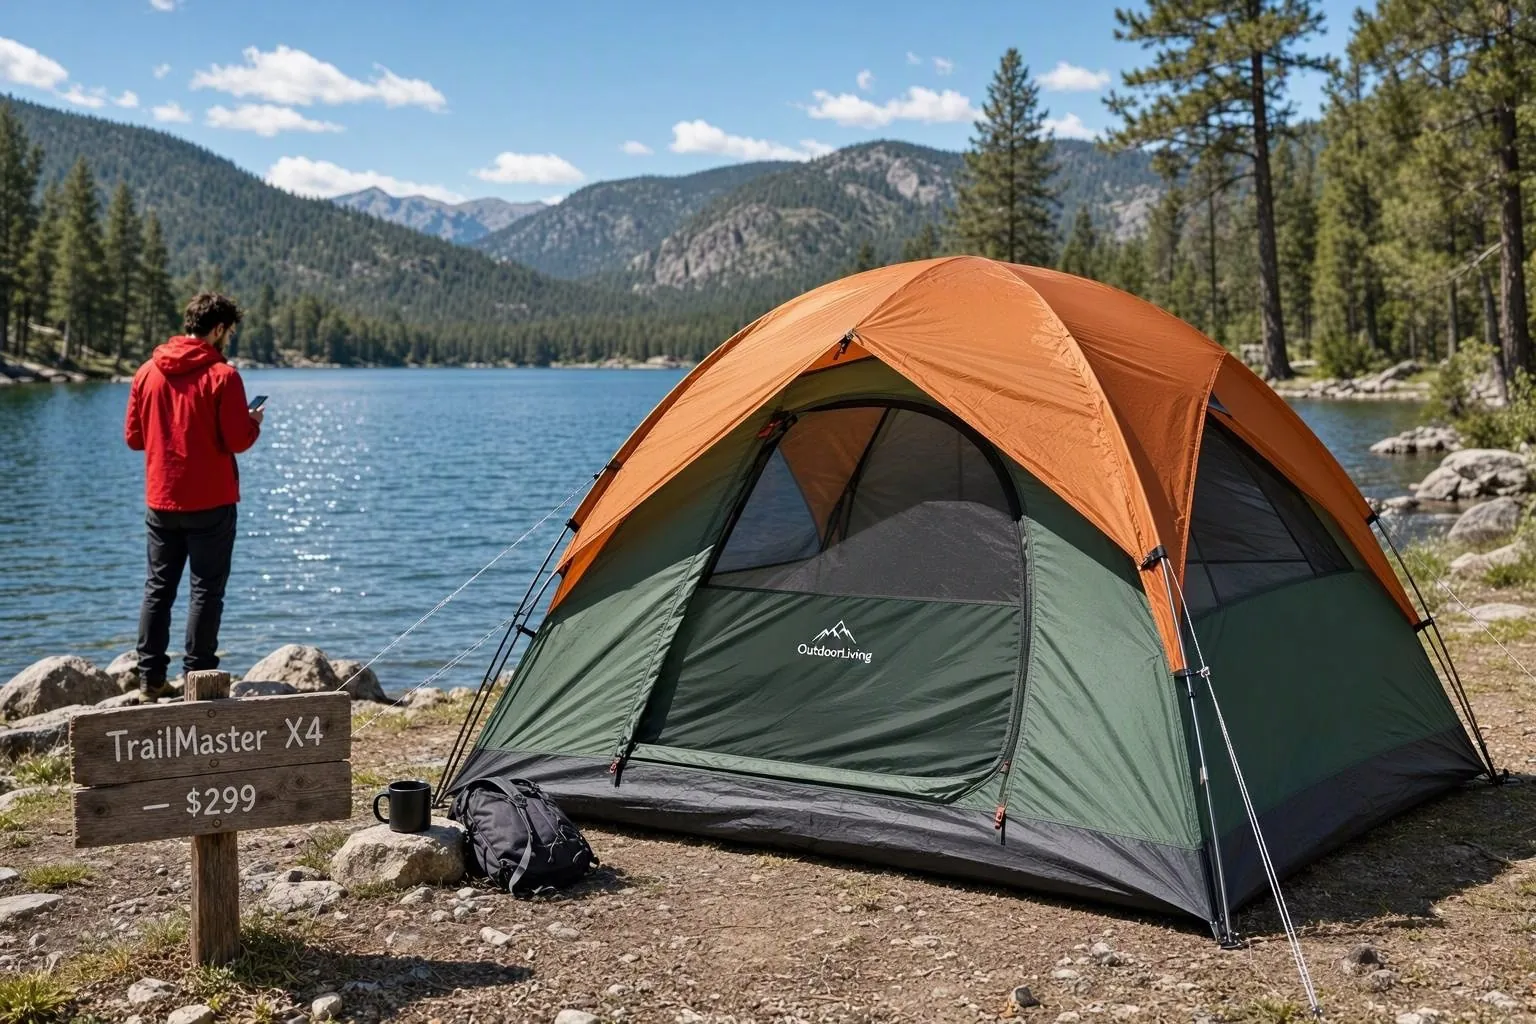

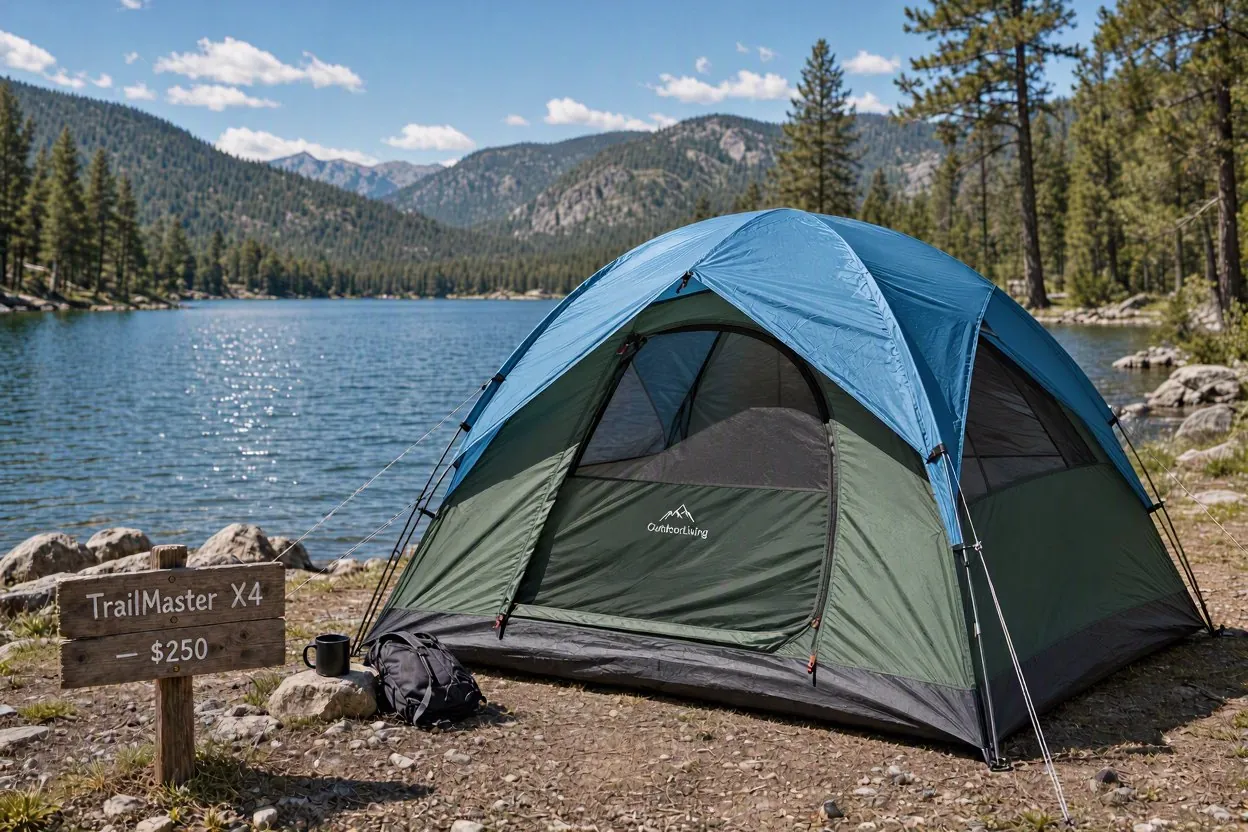

   Waiting 9 s for the rate limit (2 requests a minute)...
   Submitted 07-h3-max-first-last (908df883...).. done in 13 s
07-h3-max-first-last: 1152x768 | 5.2 s | 24 fps | audio | made in 14 s | (example)


▶️ [07-h3-max-first-last.mp4](examples/07-h3-max-first-last.mp4)

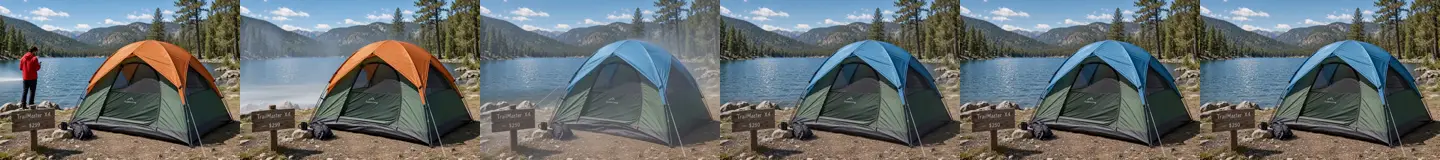

In [9]:
display(Picture(filename=str(IMAGES / "campsite-before.webp"), width=280), Picture(filename=str(IMAGES / "campsite-after.webp"), width=280))

reveal = fal["h3-max"].run("07-h3-max-first-last", "image-to-video", image_url=as_url(IMAGES / "campsite-before.webp"),
                           end_image_url=as_url(IMAGES / "campsite-after.webp"), prompt_expansion_mode="disabled",
                           prompt="A gust of wind crosses the lake; as it passes, the tent's rainfly changes to its new color. Static camera. Audio: wind, water lapping.",
                           seed=SEED, duration=5, resolution="768P")
clips.append(reveal)
show(reveal, frames=6)

**What to look for:** the first and last frames should match the two images. In between, the lake, trees, and shadows should stay put; only the rainfly should change. Kling and LTX also take start and end images; the [MiniMax H3 Max capsule](../../4-models/fal-minimax-h3-max/) adds a middle frame.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 8. Is the fast tier good enough for drafts?

MiniMax H3 Max Turbo runs the same text and image modes as H3 Max, faster. We send it the claymation story from section 6, unchanged, and compare.

> 🔮 **Guess first:** how much faster will Turbo be? What will it get wrong that Max got right?

   Submitted 08-h3-turbo-claymation-text (d4143c26...)... done in 19 s
06-h3-max-claymation-text: 1344x768 | 6.6 s | 24 fps | audio | made in 19 s | (example)


▶️ [06-h3-max-claymation-text.mp4](examples/06-h3-max-claymation-text.mp4)

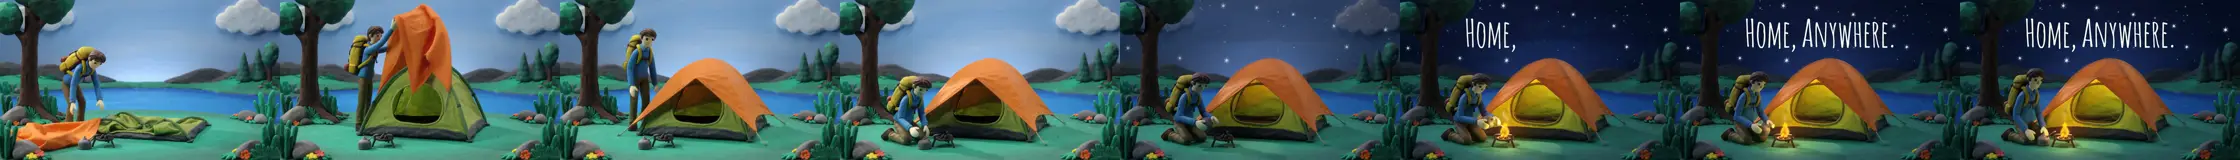

08-h3-turbo-claymation-text: 1344x768 | 6.6 s | 24 fps | audio | made in 19 s | (example)


▶️ [08-h3-turbo-claymation-text.mp4](examples/08-h3-turbo-claymation-text.mp4)

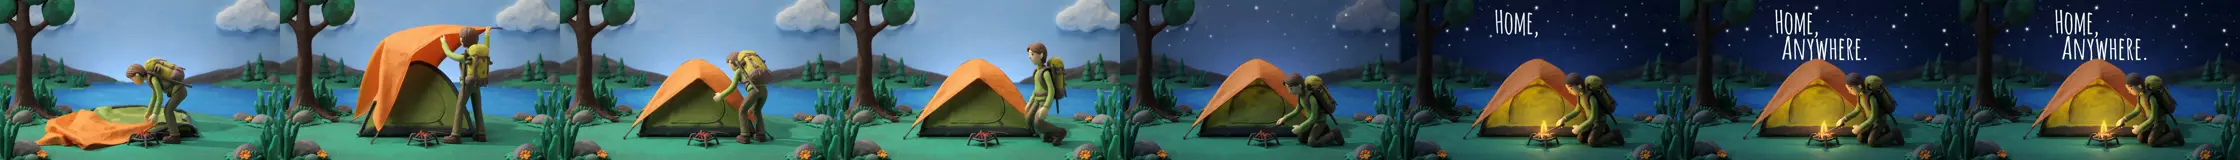

06-h3-max-claymation-text: made in 18.8 s
08-h3-turbo-claymation-text: made in 19.2 s


In [10]:
clay_turbo = fal["h3-turbo"].run("08-h3-turbo-claymation-text", "text-to-video", prompt=CLAY, **H3)
clips.append(clay_turbo)
show(clay_max, clay_turbo, frames=8)
for clip in (clay_max, clay_turbo):
    print(f"{clip.name}: made in {clip.record.get('seconds', '-')} s")

**What to look for:** compare the time first, then the details that matter for the job: are the words still spelled right, does the clay style hold, are the beats in order? If Turbo gets the idea right, it's the draft model; we switch to Max for the final.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

### 🔧 Break it on purpose

Each model has its own limits, and a request that works on one can fail on another. LTX 2.5 Pro takes 6, 8, or 10 seconds (or `auto`); MiniMax happily takes 5. What happens if we send LTX a 5?

In [11]:
if MODE == "live":
    try:
        fal["ltx-pro"].run("break-ltx-pro-5-seconds", "text-to-video/pro", prompt=BRIEF, duration=5, resolution="720p")
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 422 for `duration` and lists the values LTX 2.5 Pro accepts.")

400 while submitting on Fal-LTX-2.5-Pro. The service rejected a setting. The message below names it; compare it with the model's limits in the At a glance table.
{"detail": "[{\"type\":\"enum\",\"loc\":[\"duration\"],\"msg\":\"Input should be 6, 8, 10 or 'auto'\",\"input\":5,\"ctx\":{\"expected\":\"6, 8, 10 or 'auto'\"},\"url\":\"https://errors.pydantic.dev/2.14/v/enum\"}]", "error_type": "schema_validation_error"}


The error names the setting and the allowed values: that's our fix. When moving a prompt between models, check each model's **Clip shape** row in its capsule: duration format (Kling uses strings like `"5"`), resolution names (`720p` vs `768P`), and frame rates all differ.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 9. Can we cut the best clips into one campaign reel?

Now we combine. Each model made the piece it's best at; we trim each clip, scale everything to 1280×720 at 25 fps (with black bars for the vertical poster), add silence where a clip has no audio, and join them. This uses ffmpeg locally, so it works in replay too and makes no Azure calls.

09-campaign-reel: 1280x720 | 31.0 s | 25 fps | audio | (example)


▶️ [09-campaign-reel.mp4](examples/09-campaign-reel.mp4)

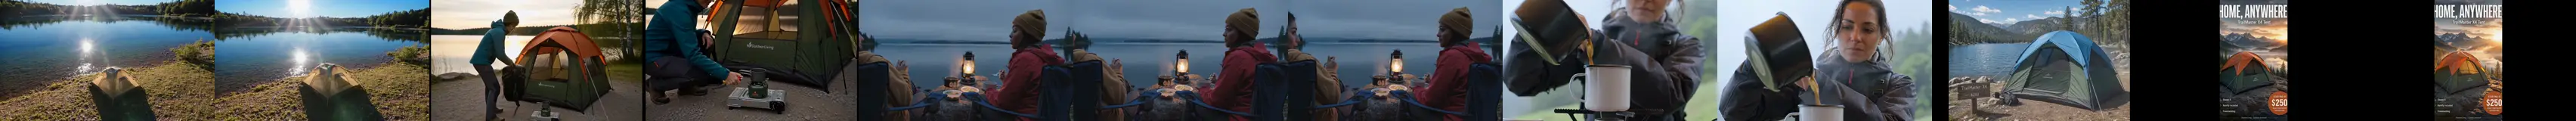

In [12]:
import subprocess

REEL = [  # (clip, start second, seconds to keep)
    (long_take, 0, 4),   # LTX Fast: establishing shot
    (weekend, 0, 6),     # H3 Max: real products in one scene
    (talk, 4, 8),        # Kling: two speakers
    (pour, 0, 4),        # Kling: physics close-up
    (reveal, 0, 5),      # H3 Max: new colorway reveal
    (poster, 0, 4),      # LTX Pro: end card with legible text
]
VF = "scale=1280:720:force_original_aspect_ratio=decrease,pad=1280:720:(ow-iw)/2:(oh-ih)/2,fps=25,setsar=1,format=yuv420p"

parts = HERE / "output" / "reel-parts"
parts.mkdir(parents=True, exist_ok=True)
listing = []
for i, (clip, start, seconds) in enumerate(REEL):
    part = parts / f"{i:02d}-{clip.name}.mp4"
    cmd = [_ffmpeg(), "-hide_banner", "-loglevel", "error", "-y", "-ss", str(start), "-t", str(seconds), "-i", str(clip.path)]
    has_audio = probe(clip.path).get("has_audio")
    if not has_audio:
        cmd += ["-f", "lavfi", "-t", str(seconds), "-i", "anullsrc=r=48000:cl=stereo"]
    cmd += ["-vf", VF, "-map", "0:v:0", "-map", "0:a:0" if has_audio else "1:a:0",
            "-c:v", "libx264", "-preset", "veryfast", "-crf", "23", "-c:a", "aac", "-ar", "48000", "-ac", "2", str(part)]
    subprocess.run(cmd, check=True)
    listing.append(f"file '{part.as_posix()}'")

(parts / "list.txt").write_text("\n".join(listing) + "\n")
reel_path = HERE / "output" / "09-campaign-reel.mp4"
subprocess.run([_ffmpeg(), "-hide_banner", "-loglevel", "error", "-y", "-f", "concat", "-safe", "0",
                "-i", str(parts / "list.txt"), "-c", "copy", str(reel_path)], check=True)

reel = Clip("09-campaign-reel", reel_path, {"probe": probe(reel_path)}, "yours")
show(reel, frames=12)

**What to look for:** the cuts between models. Color, grain, and sound change at every join, because each model has its own look. That's the honest cost of mixing models: a real edit would color-grade and mix audio across the reel. The upside is that each piece came from the model best suited to it.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 10. Which model should we choose for each job?

### Scoreboard

Every clip we generated, from its saved record: how long it took, the duration we asked for vs the one we got, and the output's shape and size.

In [13]:
scoreboard(clips)

clip                                made in  asked    got       size   fps     MB audio
01-brief-kling                      257.6 s      6   6.04  1920x1080  24.0  24.18 yes
01-brief-ltx-pro                    308.8 s      6    6.0   1280x720  25.0   5.59 yes
01-brief-ltx-fast                    87.2 s      6    6.0   1280x720  25.0    3.0 yes
01-brief-h3-max                      18.8 s      6   6.59   1344x768  24.0   8.41 yes
01-brief-h3-turbo                    19.0 s      6   6.59   1344x768  24.0   8.35 yes
02-kling-multishot-dialogue         348.5 s     12  12.05  1920x1080  24.0  33.98 yes
03-kling-physics                    182.8 s      5   5.04  1920x1080  24.0   15.4 yes
04-ltx-pro-poster-text               92.5 s      6    6.0  1080x1920  25.0   4.06 no
04-ltx-pro-crowd-motion             360.3 s      6    6.0  1920x1080  50.0  21.63 yes
05-ltx-fast-twenty-seconds          167.6 s     20   20.0   1280x720  24.0  10.44 yes
05-ltx-fast-4k-loop                 257.4 s      6   

**When to choose each model**, from what we saw here and in each capsule:

- **[Kling V3 Pro](../../4-models/fal-kling-v3-pro/):** multi-shot scenes we direct shot by shot, dialogue with lip sync, consistent characters, and realistic physics and camera moves. Needs a US Data Zone deployment.
- **[LTX 2.5 Pro](../../4-models/fal-ltx-2.5-pro/):** hero clips where on-screen text, faces, and fast or crowded motion must stay sharp; camera presets; 50 fps.
- **[LTX 2.5 Fast](../../4-models/fal-ltx-2.5-fast/):** drafts in volume, single takes up to 20 seconds, and 4K.
- **[MiniMax H3 Max](../../4-models/fal-minimax-h3-max/):** real products and people from reference images in one scene, beats in the order written, set art styles, and first, middle, and last frames.
- **[MiniMax H3 Max Turbo](../../4-models/fal-minimax-h3-max-turbo/):** fast drafts of H3 Max text and image prompts before a final render on Max.

Some features from the release aren't shown here: LTX's EXR output and native multishot aren't exposed through the Foundry routes these notebooks use, and Kling's video-based elements need a 3–8 second reference clip.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Swap the specialists.** Send the section 2 storyboard to H3 Max as one prompt with the beats in order. Which model keeps Maya and Lucía distinct?
- **Draft, then final.** Make the section 6 four-product scene on Turbo with the start frame `lifestyle-all-products.webp` (Turbo has no reference mode). How close does it get?
- **Recut the reel.** Change `REEL` in section 9: a vertical cut for phones, or a 15-second version with only three clips.

In [14]:
# Your experiment here. Try: fal["h3-turbo"].run("my-clip", "text-to-video", prompt="...", duration=5, resolution="480P")

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Gave all five models the same brief and compared speed, look, and sound
- ✅ Handed each model its specialty: multi-shot dialogue, physics, sharp text and motion, long and 4K takes, real products in one scene
- ✅ Checked whether Turbo is good enough for drafts
- ✅ Cut the best clips into one campaign reel and listed when to choose each model

➡️ **Next:** go deeper on any model in its capsule, starting with [Kling V3 Pro](../../4-models/fal-kling-v3-pro/) or [MiniMax H3 Max](../../4-models/fal-minimax-h3-max/).

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Fal models on Microsoft Foundry](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models) · [Video Generation primer](../../3-primers/video-generation.md) · [fal model gallery](https://fal.ai/models)